# Clasificación de textos en esperanto: física, biología y química

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danielaagonzalezz/cienciaNLP/blob/main/notebooks/clasificacion_esperanto.ipynb)

**Minería de Textos · 4º INF-A · CUNEF · 2026/2027**

**Equipo:** Daniela González ([@danielaagonzalezz](https://github.com/danielaagonzalezz)) · Olivia ([@Olivia029](https://github.com/Olivia029))

**Repositorio:** https://github.com/danielaagonzalezz/cienciaNLP

---

Este cuaderno es la **Fase 3** de la práctica. Usa lo que hicimos en las dos primeras, que está en el repositorio:

1. **Dataset** (`dataset/dataset.csv`): párrafos de la Wikipedia en esperanto etiquetados como `fiziko`, `biologio` o
   `kemio`. Lo genera el script `scripts/build_dataset.py`.
2. **Librería `ciencianlp`**: tokenizador, lematizador, POS-tagger y stop-words, basada en reglas y hecha desde cero.

Con ellos el cuaderno **vectoriza el corpus, entrena un clasificador, lo evalúa y clasifica páginas web reales**.

Hemos elegido física, biología y química porque son **temáticas cercanas**: comparten vocabulario científico
(*energio*, *molekulo*, *ĉelo*, *atomo*...), así que separarlas no es trivial.

**Independencia de temática:** el cuaderno no tiene las clases escritas en ningún sitio, las lee del dataset. Basta
con cambiar `URL_DATASET` (y la lista de páginas web `PAGINAS`) para reentrenarlo y evaluarlo con el dataset de otro
equipo que cumpla el contrato de datos.

## Índice

0. Configuración
1. Dataset: descarga y comprobación del contrato de datos
2. Procesado con `ciencianlp`
3. Exploración del dataset
4. Modelo de clasificación
5. Clasificación de páginas web
6. Conclusiones

El cuaderno se ejecuta de principio a fin con **Entorno de ejecución → Ejecutar todas**, sin GPU y en menos de un
minuto.

## 0. Configuración

Todos los parámetros están en esta celda, para que el cuaderno se ejecute sin preguntar nada al usuario.

- `URL_DATASET`: dataset que se usa. Por defecto, el nuestro; se puede poner el de otro equipo.
- `URL_DATASET_RESPALDO`: copia del mismo fichero en otro servidor, por si el primero no responde.
- `SEMILLA`: se fija para que los resultados sean reproducibles.

In [1]:
REPO = "danielaagonzalezz/cienciaNLP"
RAMA = "main"  # rama de la que se instala la librería y se lee el dataset

URL_DATASET = f"https://raw.githubusercontent.com/{REPO}/{RAMA}/dataset/dataset.csv"
URL_DATASET_RESPALDO = f"https://cdn.jsdelivr.net/gh/{REPO}@{RAMA}/dataset/dataset.csv"  # None si no hay copia

SEMILLA = 42

### Instalación

En Colab ya vienen `pandas`, `scikit-learn`, `matplotlib`, `requests` y `beautifulsoup4`. Solo falta nuestra
librería, que se instala con `pip` directamente desde el repositorio de GitHub.

In [2]:
!pip install -q git+https://github.com/danielaagonzalezz/cienciaNLP.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import math
import random
import re
from collections import Counter

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import sklearn

import ciencianlp
from ciencianlp import nlp

random.seed(SEMILLA)
np.random.seed(SEMILLA)
pd.set_option("display.max_colwidth", 220)

# Versiones usadas, para poder reproducir los resultados
for libreria in (ciencianlp, pd, np, sklearn, matplotlib, requests):
    print(f"{libreria.__name__:<12} {libreria.__version__}")

ciencianlp   0.1.0
pandas       2.2.3
numpy        2.4.6
sklearn      1.6.1
matplotlib   3.10.0
requests     2.34.2


## 1. Dataset

### 1.1 Descarga

El dataset se descarga automáticamente del repositorio de GitHub. Para que el cuaderno no falle si GitHub no responde,
si la primera URL falla se prueba la copia del CDN jsDelivr, que sirve el mismo fichero del mismo repositorio.

In [4]:
try:
    df = pd.read_csv(URL_DATASET, sep=";")
except Exception:  # sin red, 404...
    print("No se pudo leer el dataset de GitHub, se usa la copia de jsDelivr")
    df = pd.read_csv(URL_DATASET_RESPALDO, sep=";")

CLASES = sorted(df["class"].unique())  # las clases salen del dataset, no se escriben a mano
print("Clases:", CLASES)
df.head()

Clases: ['biologio', 'fiziko', 'kemio']


,text,class
0,Bruŝirmiloj antaŭ ĉio estas uzataj por redukti la bruon de vojtrafiko aŭ reltrafiko. Ekzistas tiel nomataj reflektaj kaj absorbaj bruŝirmiloj. Ĉe reflektaj bruŝirmiloj oni parolas pri reflektado de la bruo. La bruabs...,fiziko
1,La funkciado de la ŝirmilo ankaŭ dependas de la amplekso de la brufonto. Tial oni bezonas laŭlonge de larĝa aŭtovojo ofte pli altan bruŝirmilon ol laŭlonge relative mallarĝa fervojo. La efiko estas plifortigita ĉar l...,fiziko
2,"sistemon de orbitantaj sunpovaj satelitoj komplete ĉirkaŭantaj stelon aŭ sunon. Tiu strukturo nomiĝas la Dajsonsfero, kiu kaptus plejparton aŭ la tuton da la energia produktokvanto de la stelo. Pri tiu koncepto, sinj...",fiziko
3,"Ekzistas aliaj variaĵoj, tielnomataj Dajsonstrukturoj. Solida ŝelo ĉirkaŭ stelo estas la Dajsonŝelo. La Dajsonringo estas orbitanta ringo ĉirkaŭ stelo ĉe la vivebla zono, ekzemple de nia Suno ĉe radiuso de 1 AU. En l...",fiziko
4,"La materikvanto, n, de specimeno aŭ sistemo estas fizika kvanto kiu estas proporcia al la nombro da elementaj entoj ĉeestantaj. ""Elementaj entoj"" povas esti atomoj, molekuloj, jonoj, elektronoj, aŭ partikloj, de kiuj...",fiziko


### 1.2 Comprobación del contrato de datos

El enunciado fija un contrato para el dataset. Lo comprobamos con `assert`, de forma que si algo no se cumple el
cuaderno se para y avisa:

- dos columnas con cabecera `text;class`,
- ningún párrafo vacío ni con el carácter `;`,
- al menos 3 clases,
- párrafos limpios: sin HTML, enlaces ni referencias del tipo `[1]`.

In [5]:
assert list(df.columns) == ["text", "class"], "Las columnas deben ser text;class"
assert df["text"].notna().all() and (df["text"].str.strip() != "").all(), "Hay párrafos vacíos"
assert not df["text"].str.contains(";").any(), "Algún párrafo contiene ';'"
assert df["class"].nunique() >= 3, "Hacen falta al menos 3 clases"

restos = r"<[a-z/][^>]*>|https?://|www\.|\[\d+\]"  # HTML, enlaces y referencias
assert not df["text"].str.contains(restos).any(), "Quedan restos de HTML, enlaces o referencias"

print(f"Contrato cumplido: {len(df)} párrafos, {df['class'].nunique()} clases")
df["class"].value_counts().rename("párrafos").to_frame()

Contrato cumplido: 1098 párrafos, 3 clases


,párrafos
class,
biologio,372
fiziko,368
kemio,358


## 2. Procesado con `ciencianlp`

Nuestra librería tiene una API parecida a la de spaCy: `nlp(texto)` devuelve un `Doc`, que se recorre token a token.
Cada `Token` trae su lema (`lemma_`), su etiqueta gramatical (`pos_`) y si es una stop-word (`is_stop`).

In [6]:
ejemplo = nlp("La elektronoj de la atomo moviĝas ĉirkaŭ la kerno.")
pd.DataFrame([{"text": t.text, "lemma_": t.lemma_, "pos_": t.pos_, "is_stop": t.is_stop, "is_alpha": t.is_alpha}
              for t in ejemplo])

,text,lemma_,pos_,is_stop,is_alpha
0,La,la,DET,True,True
1,elektronoj,elektrono,NOUN,False,True
2,de,de,ADP,True,True
3,la,la,DET,True,True
4,atomo,atomo,NOUN,False,True
5,moviĝas,moviĝi,VERB,False,True
6,ĉirkaŭ,ĉirkaŭ,ADP,True,True
7,la,la,DET,True,True
8,kerno,kerno,NOUN,False,True
9,.,.,PUNCT,False,False


### 2.1 Palabras de cada párrafo

Igual que en el ejercicio 06 de clase, de cada párrafo nos quedamos con los **lemas** de las palabras que aportan
información sobre el tema:

- solo palabras (`is_alpha`): fuera signos y números;
- sin **stop-words** (*la*, *de*, *kaj*, *estas*...), que aparecen igual en las tres clases;
- solo las categorías gramaticales de `POS_TAGS`, según **nuestro POS-tagger**: sustantivos, adjetivos, verbos y `X`
  (nombres propios y siglas). Los adverbios y el resto de palabras gramaticales no ayudan a distinguir el tema;
- en forma de **lema**, para que *ĉelo*, *ĉeloj*, *ĉelon* y *ĉelojn* cuenten como la misma palabra.

In [7]:
POS_TAGS = {"NOUN", "ADJ", "VERB", "X"}


def words_of(doc):
    """Los lemas de las palabras de un Doc que pasan los filtros."""
    words = []
    for token in doc:
        if token.is_alpha and not token.is_stop and token.pos_ in POS_TAGS:
            words.append(token.lemma_)
    return words


docs = [nlp(texto) for texto in df["text"]]
df["lemas"] = [words_of(doc) for doc in docs]
df[["text", "lemas"]].head(3)

,text,lemas
0,Bruŝirmiloj antaŭ ĉio estas uzataj por redukti la bruon de vojtrafiko aŭ reltrafiko. Ekzistas tiel nomataj reflektaj kaj absorbaj bruŝirmiloj. Ĉe reflektaj bruŝirmiloj oni parolas pri reflektado de la bruo. La bruabs...,"[bruŝirmilo, uzata, redukti, bruo, vojtrafiko, reltrafiko, ekzisti, nomata, reflekta, absorba, bruŝirmilo, reflekta, bruŝirmilo, paroli, reflektado, bruo, bruabsorba, ŝirmilo, alta, kvalito, bruo, ŝirmilo, absorbi, m..."
1,La funkciado de la ŝirmilo ankaŭ dependas de la amplekso de la brufonto. Tial oni bezonas laŭlonge de larĝa aŭtovojo ofte pli altan bruŝirmilon ol laŭlonge relative mallarĝa fervojo. La efiko estas plifortigita ĉar l...,"[funkciado, ŝirmilo, dependi, amplekso, brufonto, bezoni, larĝa, aŭtovojo, alta, bruŝirmilo, mallarĝa, fervojo, efiko, plifortigita, aŭtovojo, rifuĝa, leno]"
2,"sistemon de orbitantaj sunpovaj satelitoj komplete ĉirkaŭantaj stelon aŭ sunon. Tiu strukturo nomiĝas la Dajsonsfero, kiu kaptus plejparton aŭ la tuton da la energia produktokvanto de la stelo. Pri tiu koncepto, sinj...","[sistemo, orbitanta, sunpova, satelito, ĉirkaŭanta, stelo, suno, strukturo, nomiĝi, dajsonsfero, kapti, plejparto, tuto, energia, produktokvanto, stelo, koncepto, sinjoro, dyso, influi, verko, stelfaranto, olaf, stap..."


In [8]:
# Cuánto reduce el vocabulario el lematizador
formas = set()
lemas = set()
for doc in docs:
    for token in doc:
        if token.is_alpha:
            formas.add(token.text.lower())
            lemas.add(token.lemma_)
print(f"Vocabulario: {len(formas)} formas distintas -> {len(lemas)} lemas "
      f"({1 - len(lemas) / len(formas):.0%} menos gracias al lematizador)")

Vocabulario: 14292 formas distintas -> 10682 lemas (25% menos gracias al lematizador)


### 2.2 Etiquetas gramaticales del corpus

Porcentaje de tokens de cada categoría gramatical en cada clase. La fila `X` son las palabras que el etiquetador no
sabe clasificar (nombres propios sin terminación esperanta, siglas, fórmulas...); sirve para ver hasta dónde llegan
las reglas.

In [9]:
filas = []
for doc, clase in zip(docs, df["class"]):
    for token in doc:
        filas.append({"class": clase, "pos": token.pos_})
etiquetas = pd.DataFrame(filas)

tabla_pos = pd.crosstab(etiquetas["pos"], etiquetas["class"], normalize="columns") * 100
tabla_pos.round(1).sort_values(CLASES[0], ascending=False)

class,biologio,fiziko,kemio
pos,,,
NOUN,23.9,23.1,22.6
PUNCT,14.7,14.7,15.9
ADP,12.8,12.3,12.9
ADJ,12.5,12.6,11.8
VERB,9.0,9.5,8.7
DET,8.5,9.0,8.1
ADV,6.8,6.4,6.2
CCONJ,3.9,3.4,3.4
PRON,3.3,3.8,3.7


## 3. Exploración del dataset

### 3.1 Tamaño de las clases y longitud de los párrafos

Comprobamos que las clases están equilibradas (si una tuviera muchos más párrafos, el modelo tendería a predecirla) y
cómo de largos son los párrafos.

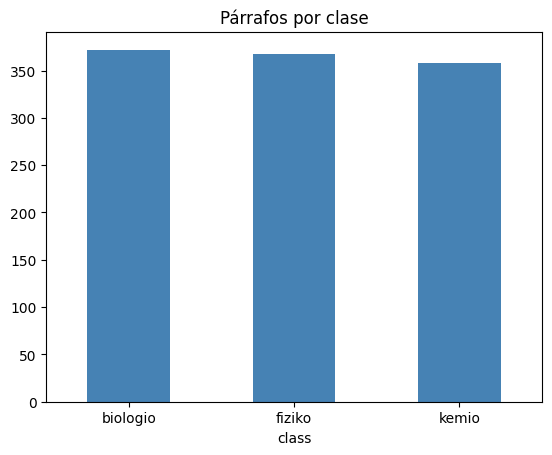

In [10]:
df["class"].value_counts().plot.bar(color="steelblue", rot=0, title="Párrafos por clase")
plt.show()

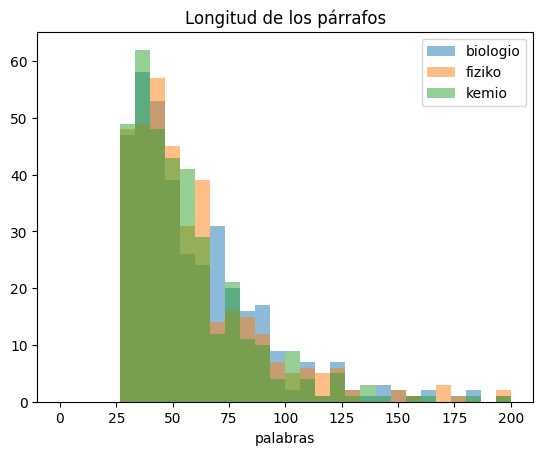

class
biologio    61.0
fiziko      60.0
kemio       56.0
Name: n_palabras, dtype: float64

In [11]:
df["n_palabras"] = df["text"].str.split().str.len()

for clase in CLASES:
    plt.hist(df[df["class"] == clase]["n_palabras"], bins=30, range=(0, 200), alpha=0.5, label=clase)
plt.title("Longitud de los párrafos")
plt.xlabel("palabras")
plt.legend()
plt.show()

df.groupby("class")["n_palabras"].mean().round(0)

### 3.2 Lemas más frecuentes por clase

Los 15 lemas más frecuentes de cada clase. Contamos en cuántos párrafos aparece cada lema, no cuántas veces, para que
un párrafo que repite mucho una palabra no pese de más.

In [12]:
frecuentes = {}
for clase in CLASES:
    contador = Counter()
    for lemas_parrafo in df[df["class"] == clase]["lemas"]:
        contador.update(set(lemas_parrafo))  # set: cada lema cuenta una vez por párrafo
    frecuentes[clase] = contador

tabla = {}
for clase in CLASES:
    tabla[clase] = [lema for lema, n in frecuentes[clase].most_common(15)]
pd.DataFrame(tabla)

,biologio,fiziko,kemio
0,povi,povi,povi
1,alia,alia,kemia
2,parto,havi,atomo
3,specio,forto,elemento
4,havi,elektra,alia
5,kelka,energio,substanco
6,homo,korpo,havi
7,granda,sistemo,molekulo
8,homa,objekto,ĥemia
9,sistemo,fiziko,elektrono


In [13]:
# Lemas que están entre los 50 más frecuentes de TODAS las clases
comunes = None
for clase in CLASES:
    top50 = {lema for lema, n in frecuentes[clase].most_common(50)}
    comunes = top50 if comunes is None else comunes & top50  # & = intersección
print(f"{len(comunes)} lemas comunes a todas las clases:", ", ".join(sorted(comunes)))

9 lemas comunes a todas las clases: alia, granda, havi, multa, povi, sistemo, strukturo, uzata, uzi


Que muchos de los lemas más frecuentes sean comunes a todas las clases confirma que las temáticas son
**cercanas**: comparten el vocabulario general de la ciencia. Por eso usaremos TF-IDF, que da menos peso a las
palabras que aparecen en todas partes.

## 4. Modelo de clasificación

### 4.1 Partición entrenamiento / test

Separamos un 20 % del dataset como **test**. No se usa hasta la evaluación final, así la nota que obtenga el modelo en
test es una estimación honesta de cómo funcionará con textos nuevos. La partición es **estratificada** (cada clase
tiene la misma proporción en train y en test) y usa la semilla fija.

In [14]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=0.2, stratify=df["class"], random_state=SEMILLA)
print(f"Entrenamiento: {len(train)} párrafos · Test: {len(test)} párrafos")
pd.DataFrame({"train": train["class"].value_counts(), "test": test["class"].value_counts()})

Entrenamiento: 878 párrafos · Test: 220 párrafos


,train,test
class,,
biologio,298,74
fiziko,294,74
kemio,286,72


### 4.2 Vectorización TF-IDF

Pasamos cada párrafo a una fila de números (representación **tabular**) con TF-IDF, igual que en el ejercicio 06:

$$
TF(t, d) = \frac{f(t, d)}{|d|}
\qquad
IDF(t) = \log\frac{N + 1}{n_t + 1} + 1
\qquad
\vec{d}[t] = TF(t, d) \cdot IDF(t)
$$

- $f(t, d)$: veces que aparece el lema $t$ en el párrafo $d$; $|d|$: lemas de $d$ que están en la bolsa de palabras.
- $N$: número de párrafos de entrenamiento; $n_t$: párrafos de entrenamiento que contienen $t$.
- Al final cada vector se **normaliza** (longitud 1), para que los párrafos largos no tengan valores más grandes.

Así, un lema que sale en casi todos los párrafos (*povi*, *havi*...) pesa poco, y uno específico (*ĉelo*,
*elektrono*...) pesa mucho.

La **bolsa de palabras** son los lemas que aparecen más de `MIN_COUNT` veces en entrenamiento: los que salen una
sola vez no ayudan a generalizar y suelen ser nombres propios o erratas. Tanto la bolsa como el IDF se calculan **solo
con los párrafos de entrenamiento**; el test se vectoriza con ellos, sin mirarlo antes.

In [15]:
MIN_COUNT = 2


def choose_words(listas, min_count):
    """La bolsa de palabras: los lemas que aparecen más de min_count veces."""
    counts = Counter()
    for words in listas:
        counts.update(words)
    return sorted(word for word, count in counts.items() if count > min_count)


def compute_idf(listas, words):
    """El IDF de cada lema de la bolsa: {lema: idf}."""
    N = len(listas)
    document_frequency = Counter()
    for text_words in listas:
        document_frequency.update(set(text_words))  # set: cada lema cuenta una vez por párrafo
    idf = {}
    for word in words:
        idf[word] = math.log((N + 1) / (document_frequency[word] + 1)) + 1
    return idf


def vectorize(listas, words, idf):
    """Una fila por párrafo y una columna por lema de la bolsa, con su TF-IDF normalizado."""
    rows = []
    for text_words in listas:
        text_words = [word for word in text_words if word in idf]  # solo los lemas de la bolsa
        counts = Counter(text_words)  # f(t, d)
        size = len(text_words)        # |d|

        row = {}
        for word in words:
            tf = counts[word] / size if size > 0 else 0.0  # TF(t, d)
            row[word] = tf * idf[word]                     # TF(t, d) * IDF(t)
        norm = math.sqrt(sum(value ** 2 for value in row.values()))
        if norm > 0:
            for word in words:
                row[word] /= norm
        rows.append(row)
    return pd.DataFrame(rows, columns=words)


WORDS = choose_words(train["lemas"], MIN_COUNT)
IDF = compute_idf(train["lemas"], WORDS)
X_train = vectorize(train["lemas"], WORDS, IDF)
X_test = vectorize(test["lemas"], WORDS, IDF)
y_train = train["class"]
y_test = test["class"]

print(f"Bolsa de palabras: {len(WORDS)} lemas")
print("X_train:", X_train.shape, "· X_test:", X_test.shape)

Bolsa de palabras: 2208 lemas
X_train: (878, 2208) · X_test: (220, 2208)


### 4.3 Comparación de modelos

Probamos los cuatro modelos vistos en clase con **validación cruzada de 5 particiones** sobre el conjunto de
entrenamiento (el test sigue sin tocarse). Medimos el **F1 macro**: la media del F1 de cada clase, que trata igual a
todas las clases.

Los parámetros de cada modelo los elegimos tras probar varios valores a mano, como en el ejercicio 06.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

MODELOS = {
    "KNN (k = 10, distancia coseno)": KNeighborsClassifier(n_neighbors=10, metric="cosine"),
    "Naive Bayes (alpha = 0.1)": MultinomialNB(alpha=0.1),
    "Regresión logística (C = 10)": LogisticRegression(C=10, max_iter=1000),
    "Árbol de decisión (profundidad 20)": DecisionTreeClassifier(max_depth=20, random_state=SEMILLA),
}

comparacion = {}
for nombre, modelo_cv in MODELOS.items():
    notas = cross_val_score(modelo_cv, X_train, y_train, cv=5, scoring="f1_macro")
    comparacion[nombre] = notas.mean()
    print(f"{nombre}: F1 macro = {notas.mean():.3f}")

KNN (k = 10, distancia coseno): F1 macro = 0.808
Naive Bayes (alpha = 0.1): F1 macro = 0.873


Regresión logística (C = 10): F1 macro = 0.861


Árbol de decisión (profundidad 20): F1 macro = 0.546


#### ¿Aporta algo nuestra librería?

Repetimos lo mismo con la regresión logística, pero **sin `ciencianlp`**: cada párrafo se parte en palabras con una
expresión regular, sin lematizar, sin quitar stop-words y sin filtrar por categoría gramatical.

Sin ciencianlp: F1 macro = 0.809


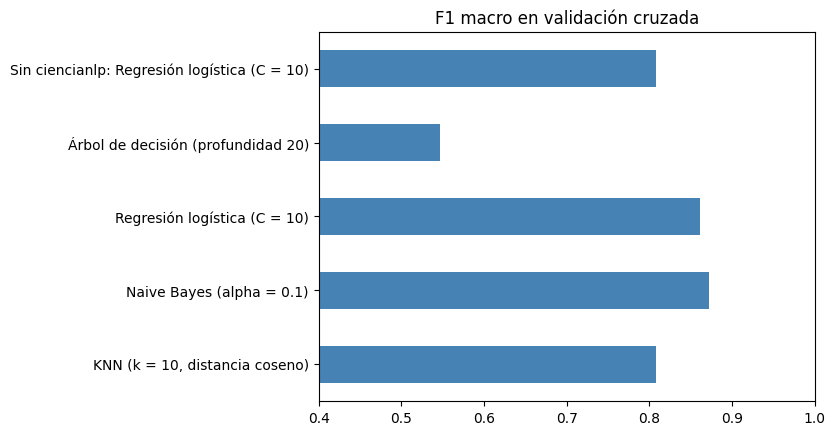

In [17]:
palabras_sin_libreria = train["text"].str.lower().str.findall(r"[^\W\d_]+")
words_sin = choose_words(palabras_sin_libreria, MIN_COUNT)
X_sin = vectorize(palabras_sin_libreria, words_sin, compute_idf(palabras_sin_libreria, words_sin))
notas_sin = cross_val_score(LogisticRegression(C=10, max_iter=1000), X_sin, y_train, cv=5, scoring="f1_macro")
comparacion["Sin ciencianlp: Regresión logística (C = 10)"] = notas_sin.mean()
print(f"Sin ciencianlp: F1 macro = {notas_sin.mean():.3f}")

pd.Series(comparacion).plot.barh(color="steelblue", xlim=(0.4, 1), title="F1 macro en validación cruzada")
plt.show()

**Qué vemos:**

- Naive Bayes (0.873) y la regresión logística (0.861) son los mejores, muy igualados; KNN va un poco por detrás y el árbol
  de decisión es claramente peor: con miles de columnas casi siempre a 0, un árbol necesita muchas preguntas para
  separar las clases, mientras que los modelos lineales suman la evidencia de todas las palabras a la vez.
- **Nuestra librería sí marca la diferencia:** sin lematizar ni filtrar, la regresión logística baja unos 5 puntos de
  F1 (de 0.861 a 0.809). Lematizar junta las formas de cada palabra (*ĉelo*, *ĉelojn*...) y el filtro de stop-words y POS quita
  palabras que no indican el tema.

### 4.4 Modelo final

Nos quedamos con la **regresión logística**. Queda muy cerca de Naive Bayes en F1 (algo más de un punto por debajo), pero sus probabilidades son más realistas
(Naive Bayes casi siempre da 0 % o 100 %), y las necesitamos para decir la probabilidad de cada clase en las páginas
web. Además, fue el mejor modelo en el ejercicio 06.

La entrenamos con todo el conjunto de entrenamiento y la evaluamos **una sola vez** en test.

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score

modelo = LogisticRegression(C=10, max_iter=1000)
modelo.fit(X_train, y_train)

pred = modelo.predict(X_test)
probas = modelo.predict_proba(X_test)

print(f"Accuracy: {accuracy_score(y_test, pred):.3f}")
print(f"F1 macro: {f1_score(y_test, pred, average='macro'):.3f}")
print()
print(classification_report(y_test, pred, digits=3))

Accuracy: 0.855
F1 macro: 0.854

              precision    recall  f1-score   support

    biologio      0.873     0.838     0.855        74
      fiziko      0.844     0.878     0.861        74
       kemio      0.847     0.847     0.847        72

    accuracy                          0.855       220
   macro avg      0.855     0.854     0.854       220
weighted avg      0.855     0.855     0.855       220



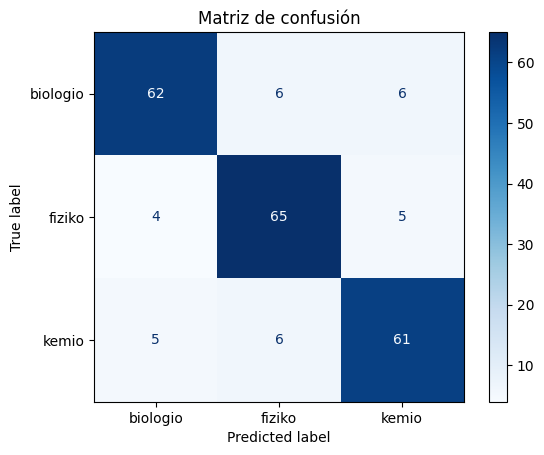

In [19]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues")
plt.title("Matriz de confusión")
plt.show()

**Qué vemos:** el resultado en test (0.854) es parecido al de la validación cruzada (0.861), así que el modelo no está
sobreajustado. Los 32 errores se reparten casi por igual entre las tres parejas de clases (10 u 11 cada una): ninguna pareja se separa claramente peor, porque las tres ciencias comparten mucho vocabulario.

### 4.5 Análisis del modelo

#### Lemas más influyentes

En la regresión logística cada clase tiene un coeficiente por lema: cuanto más alto, más empuja ese lema hacia la
clase.

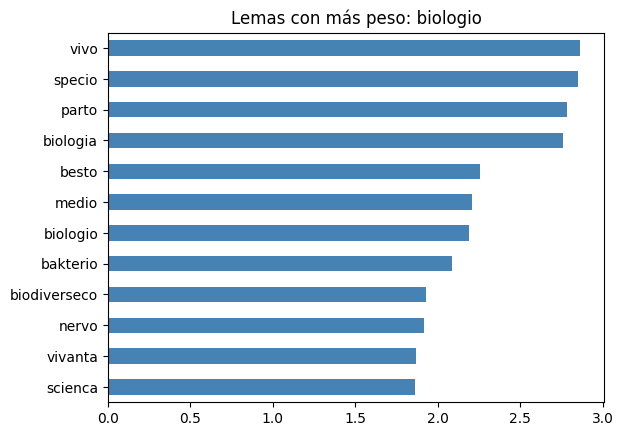

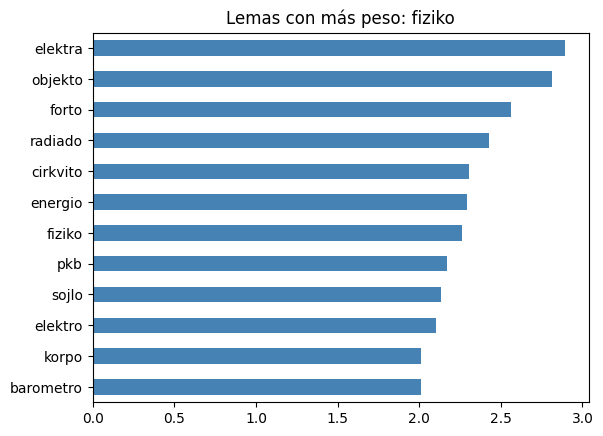

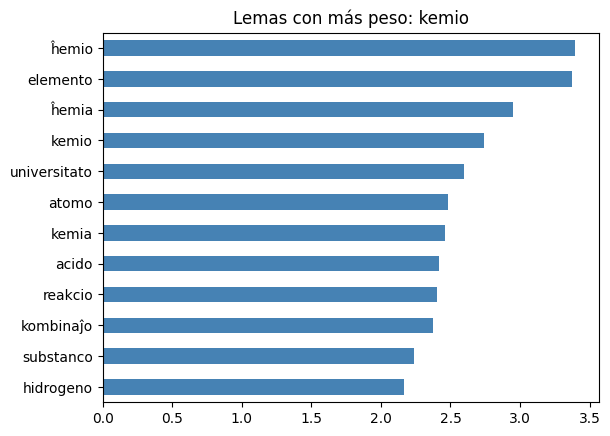

In [20]:
for i in range(len(modelo.classes_)):
    clase = modelo.classes_[i]
    pesos = pd.Series(modelo.coef_[i], index=WORDS)  # coeficiente de cada lema para esta clase
    pesos.nlargest(12).sort_values().plot.barh(color="steelblue", title=f"Lemas con más peso: {clase}")
    plt.show()

**Qué vemos:**

- La mayoría de los lemas son vocabulario propio de cada ciencia (*vivo*, *specio*, *bakterio*, *biodiverseco* /
  *elektra*, *forto*, *radiado*, *cirkvito* / *elemento*, *atomo*, *acido*, *reakcio*), así que el modelo aprende el tema y no casualidades.
- Algunos lemas delatan el **ruido** del dataset: *universitato* en química viene de las biografías de químicos (dónde estudiaron o enseñaron), que heredan la etiqueta de su artículo aunque no hablen de química.
- También se ve una limitación de la librería: *ĥemio* y *kemio* son la misma palabra (la grafía con *ĥ* es la
  antigua) y quedan como lemas distintos. Normalizar *ĥ* → *k* en el lematizador los juntaría.

#### Confianza del modelo

Probabilidad que da el modelo a la clase que predice, separando aciertos y errores. Un buen modelo debería
equivocarse sobre todo cuando duda.

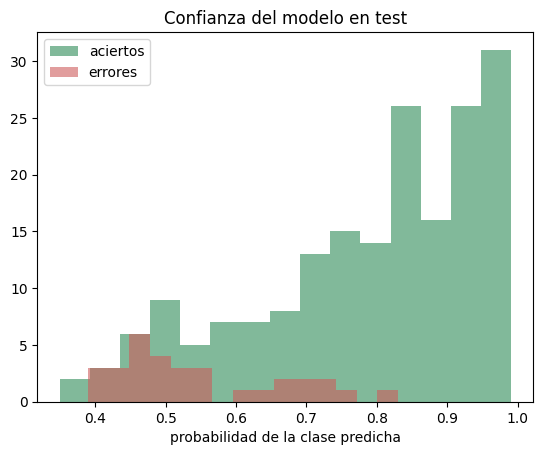

Confianza media en los aciertos: 0.78
Confianza media en los errores:  0.55


In [21]:
resultados_test = test[["class", "text"]].copy()
resultados_test["pred"] = pred
resultados_test["confianza"] = probas.max(axis=1).round(2)  # probabilidad de la clase predicha

aciertos = resultados_test[resultados_test["pred"] == resultados_test["class"]]
errores = resultados_test[resultados_test["pred"] != resultados_test["class"]]

plt.hist(aciertos["confianza"], bins=15, alpha=0.6, label="aciertos", color="seagreen")
plt.hist(errores["confianza"], bins=15, alpha=0.6, label="errores", color="indianred")
plt.title("Confianza del modelo en test")
plt.xlabel("probabilidad de la clase predicha")
plt.legend()
plt.show()

print("Confianza media en los aciertos:", aciertos["confianza"].mean().round(2))
print("Confianza media en los errores: ", errores["confianza"].mean().round(2))

#### Ejemplos de predicciones correctas e incorrectas

In [22]:
print("Aciertos con más confianza:")
display(aciertos.sort_values("confianza", ascending=False).head(3))
print("Errores con más confianza:")
display(errores.sort_values("confianza", ascending=False).head(6))

Aciertos con más confianza:


,class,text,pred,confianza
1052,kemio,Ĥemiistoj studas la ĥemiajn elementojn. Ĉiu elemento havas nur unu specon de atomo. En la ĥemio la elementoj diferencas laŭ la nombro de la elektronoj en siaj atomoj kaj laŭ siaj atompezoj. Ĉiu atomo de iu elemento h...,kemio,0.99
737,biologio,"La centra nerva sistemo en tio ĉiam ""peras"" en du direktojn: kiel centra integriga, kunordiga kaj reguliga organo ĝi ne nur prilaboras signalojn de ekster la organismo, sed ankaŭ tiujn de en la organismo. Bestoj tial...",biologio,0.99
1047,kemio,"Ĥemia ekvacio (aŭ ekvacio de ĥemia reakcio) aŭ kemia reakcio estas simbola reprezento de ĥemia reakcio per ĥemiaj formuloj, nombraj koeficientoj kaj matematikaj simboloj, sur la maldekstra flanko de kiuj aperas la ko...",kemio,0.99


Errores con más confianza:


,class,text,pred,confianza
740,kemio,"La alkohola trinkaĵo mastiĥo (greke μαστίχα [mastiĥa]) estas likvoro spicita per lentiska rezino, prenita de la lentisko, malgranda ĉiamverda arbo indiĝena de la mediteranea regiono, kiu kreskas sur la insulo Ĥio. An...",biologio,0.83
416,biologio,Planeda loĝebleco mezuras la potencialon de kosma korpo por subteni vivon. Ĝi estas aplikebla al la planedoj kaj iliaj satelitoj. La nura absoluta postulo por la vivo estas fonto de energio.,fiziko,0.76
116,fiziko,"La struktura biologio estas branĉo de la molekula biologio, la biokemio kaj de la biofiziko kiu studas la strukturon de biologiaj makromolekuloj kiaj la proteinoj kaj la nukleacidoj, la originon de tiu strukturo kaj ...",biologio,0.74
811,kemio,"Ili baziĝas sur maso, volumeno, aŭ materikvanto. Ne ĉiam estas facile konverti de iu notacio al alia, ĉar foje oni ankaŭ bezonas plian informon, ekzemple pri denso. Eble tia informo ne disponeblas, precipe se la temp...",fiziko,0.72
625,biologio,"La ADW estis kreita de Philip Myers, biologia profesoro ĉe la Universitato de Miĉigano, en 1995. Ĉiu informero estas verkita de kaj studentoj kaj instruistoj de 30 altlernejoj kaj universitatoj de Usono. Speciinforma...",kemio,0.70
931,kemio,"Rutino, ankaŭ nomata rutozido, kverketino-3-rutinozido kaj soforino estas citrusa flavonoida glikozido trovita en plej grandaj kvantoj en fagopiro, folioj kaj petioloj de rabarbo kaj fruktoj de Brazilia arbo Dimorpha...",biologio,0.70


**Qué vemos:** muchos de los "errores" más seguros no son fallos del modelo, sino **párrafos mal etiquetados**:
el modelo reconoce el tema real del párrafo, pero la etiqueta heredada del artículo es otra (por ejemplo, un párrafo
sobre un licor, el *mastiĥo*, etiquetado como química, o uno que define la biología estructural etiquetado como física). Es el **ruido** que introduce heredar la etiqueta del artículo; con el
script `scripts/medir_ruido.py` lo medimos y sale que, como mucho, un 23 % de los párrafos son posible ruido (ver README). Las referencias bibliográficas que se
colaban en el dataset (21 filas, casi todas en inglés) ya las quita `scripts/clean_dataset.py`.

## 5. Clasificación de páginas web

### 5.1 Clasificar un texto nuevo

Para clasificar cualquier texto se hace exactamente lo mismo que con el dataset: `ciencianlp` saca sus lemas
(`words_of`), se vectorizan con la misma bolsa de palabras e IDF del entrenamiento (`vectorize`) y el modelo da la
probabilidad de cada clase.

In [23]:
def clasificar(textos):
    """Probabilidad de cada clase para una lista de textos (una fila por texto)."""
    listas = [words_of(nlp(texto)) for texto in textos]
    X = vectorize(listas, WORDS, IDF)
    return pd.DataFrame(modelo.predict_proba(X), columns=modelo.classes_)


frases = [
    "La elektronoj moviĝas ĉirkaŭ la atomkerno pro la elektromagneta forto.",
    "La ĉeloj de la plantoj enhavas kloroplastojn kaj DNA.",
    "Kiam oni miksas acidon kun bazo, okazas kemia reakcio kaj formiĝas salo kaj akvo.",
]
clasificar(frases).round(2)

,biologio,fiziko,kemio
0,0.02,0.90,0.08
1,0.81,0.11,0.07
2,0.01,0.01,0.98


### 5.2 Extracción del texto de una página web (*web scraping*)

Como en el ejercicio 08, descargamos la página con `requests` y buscamos las etiquetas con `BeautifulSoup`:

1. La zona del contenido principal: `div.mw-parser-output` en Wikipedia o, si no existe, todo el `<body>`. Así se
   evitan menús y pies de página.
2. Quitamos las referencias (`<sup>`, los `[1]`) y las tablas.
3. Cogemos los párrafos (`<p>`), cambiamos el `;` por `,` como en el dataset y descartamos los que tienen menos de
   `MIN_PALABRAS_WEB` palabras (pies de foto, fórmulas sueltas...).

**Robustez:** todo va dentro de un `try`/`except`. Si la web no responde, no existe o devuelve un error, la función
avisa y devuelve una lista vacía, y el cuaderno sigue con las demás páginas.

In [24]:
from bs4 import BeautifulSoup

MIN_PALABRAS_WEB = 20
CABECERAS = {"User-Agent": f"ciencianlp-practica/1.0 (https://github.com/{REPO}; proyecto educativo)"}


def extraer_parrafos(url):
    """Párrafos limpios de una página web. Si algo falla, avisa y devuelve una lista vacía."""
    try:
        response = requests.get(url, headers=CABECERAS, timeout=20)
        response.raise_for_status()  # error si la página devuelve 404, 500...
    except Exception:
        print("No se pudo leer", url)
        return []

    soup = BeautifulSoup(response.text, "html.parser")
    zona = soup.find("div", class_="mw-parser-output")  # contenido del artículo en Wikipedia
    if zona is None:
        zona = soup.body  # otras webs: toda la página
    for etiqueta in zona.find_all(["sup", "table"]):
        etiqueta.decompose()  # fuera referencias [1] y tablas

    parrafos = []
    for p in zona.find_all("p"):
        texto = p.get_text().strip().replace(";", ",")
        palabras = re.findall(r"[^\W\d_]{3,}", texto)  # palabras de 3 letras o más (no fórmulas)
        if len(palabras) >= MIN_PALABRAS_WEB:
            parrafos.append(texto)
    return parrafos

### 5.3 Páginas elegidas

Elegimos artículos de la Wikipedia en esperanto de cada temática. Para que la prueba sea justa, ninguno de ellos se
usó para construir el dataset (lo comprobamos abajo). De biología ponemos dos: *Ekologio*, claramente biológico, y
*Fotosintezo*, un tema de frontera entre biología y química (bioquímica). Además añadimos:

- **Una página de control fuera de tema** (fútbol): el modelo solo conoce tres clases y siempre elige una.
- **Una URL que no existe**, para comprobar que el cuaderno sobrevive a una web caída.

Para usar el cuaderno con otro dataset basta con cambiar esta lista.

In [25]:
PAGINAS = {
    "Termodinamiko (física)": "https://eo.wikipedia.org/wiki/Termodinamiko",
    "Ekologio (biología)": "https://eo.wikipedia.org/wiki/Ekologio",
    "Fotosintezo (biología, frontera con química)": "https://eo.wikipedia.org/wiki/Fotosintezo",
    "Organika kemio (química)": "https://eo.wikipedia.org/wiki/Organika_kemio",
    "Futbalo (control, fuera de tema)": "https://eo.wikipedia.org/wiki/Futbalo",
    "Web caída (prueba de robustez)": "https://esta-web-no-existe.invalid/pagxo",
}

parrafos_web = {}
for nombre, url in PAGINAS.items():
    parrafos = extraer_parrafos(url)
    if parrafos:  # las páginas que fallan no se añaden
        parrafos_web[nombre] = parrafos
        print(f"{nombre}: {len(parrafos)} párrafos")

Termodinamiko (física): 34 párrafos


Ekologio (biología): 28 párrafos


Fotosintezo (biología, frontera con química): 31 párrafos


Organika kemio (química): 31 párrafos


Futbalo (control, fuera de tema): 37 párrafos
No se pudo leer https://esta-web-no-existe.invalid/pagxo


In [26]:
# ¿Algún párrafo de las páginas está en el dataset? Buscamos un trozo de 8 palabras de cada uno en el corpus.
corpus = " ".join(df["text"])
for nombre, parrafos in parrafos_web.items():
    repetidos = 0
    for parrafo in parrafos:
        trozo = " ".join(parrafo.split()[2:10])
        if trozo in corpus:
            repetidos += 1
    print(f"{nombre}: {repetidos} de {len(parrafos)} párrafos aparecen en el dataset")

Termodinamiko (física): 0 de 34 párrafos aparecen en el dataset
Ekologio (biología): 0 de 28 párrafos aparecen en el dataset
Fotosintezo (biología, frontera con química): 0 de 31 párrafos aparecen en el dataset
Organika kemio (química): 0 de 31 párrafos aparecen en el dataset
Futbalo (control, fuera de tema): 0 de 37 párrafos aparecen en el dataset


### 5.4 Resultados

Clasificamos **cada párrafo** por separado y calculamos la probabilidad de la página como la **media** de las
probabilidades de sus párrafos. Lo hacemos así porque el modelo se entrenó con párrafos, y porque la media refleja
cuánta parte de la página habla de cada tema.

,biologio,fiziko,kemio,predicción
Termodinamiko (física),0.22,0.46,0.32,fiziko
Ekologio (biología),0.77,0.13,0.10,biologio
"Fotosintezo (biología, frontera con química)",0.18,0.16,0.66,kemio
Organika kemio (química),0.15,0.12,0.73,kemio
"Futbalo (control, fuera de tema)",0.49,0.31,0.20,biologio


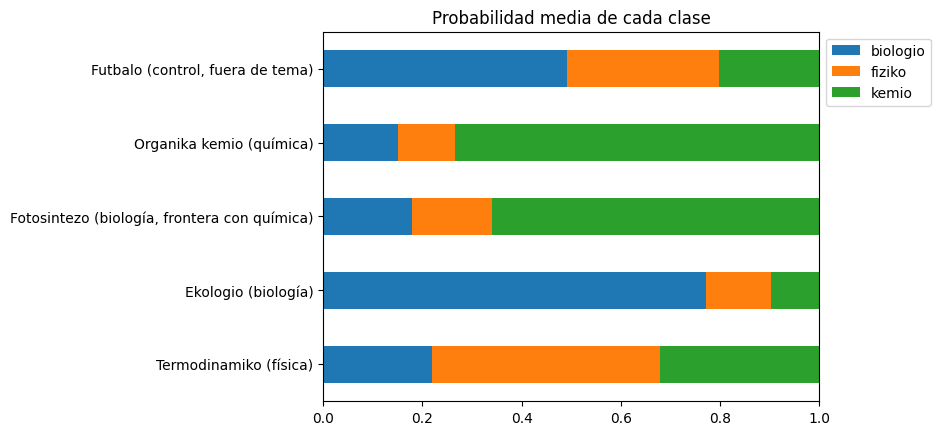

In [27]:
resultados = {}
for nombre, parrafos in parrafos_web.items():
    resultados[nombre] = clasificar(parrafos).mean()  # media de las probabilidades de sus párrafos

if resultados:
    resultados = pd.DataFrame(resultados).T
    resultados["predicción"] = resultados[CLASES].idxmax(axis=1)
    display(resultados.round(2))

    resultados[CLASES].plot.barh(stacked=True, xlim=(0, 1), title="Probabilidad media de cada clase")
    plt.legend(bbox_to_anchor=(1, 1))
    plt.show()
else:
    print("No se pudo descargar ninguna página: se omite la clasificación web.")

### 5.5 Análisis de los resultados web

- **Ekologio** (≈ 77 % biología), **Organika kemio** (≈ 73 % química) y **Termodinamiko** (≈ 46 % física) se
  clasifican bien. La termodinámica tiene bastante probabilidad de química (≈ 32 %), y tiene sentido: habla de calor,
  energía, presión y gases, que también son conceptos de química física.
- **Fotosintezo** sale como **química** (≈ 66 %). No es un error absurdo: el artículo explica la fotosíntesis a nivel
  molecular (CO₂, glucosa, clorofila, oxidación...), que es **bioquímica**. Es justo el tipo de texto de frontera que
  hace que las temáticas sean cercanas. Los párrafos más "biológicos" (los cloroplastos, las plantas) sí reparten la
  probabilidad hacia biología.
- La página de **fútbol** sale como biología, pero con una probabilidad baja (≈ 49 %) y repartida. El modelo
  **siempre** elige una de las tres clases que conoce, aunque el texto no sea de ninguna; el vocabulario sobre personas
  y su cuerpo se parece más al de biología. Para detectar textos fuera de tema haría falta una cuarta clase "otros" en
  el dataset, o rechazar las páginas cuya probabilidad máxima no supere un umbral.
- La **web caída** no detiene el cuaderno: se avisa del error y se sigue con el resto de páginas.

## 6. Conclusiones

### Resultados

- **Dataset:** unos 1100 párrafos de la Wikipedia en esperanto, equilibrados entre `fiziko`, `biologio` y `kemio`, que
  cumplen el contrato de datos. Las tres temáticas comparten mucho vocabulario científico, así que el problema no es
  trivial.
- **Librería `ciencianlp`:** procesa todo el corpus en menos de un segundo y solo deja sin etiquetar (`X`) en torno
  al 3 % de los tokens. Usarla para lematizar y filtrar por stop-words y POS **mejora el F1 macro unos 5 puntos**
  frente a usar las palabras tal cual. Es la mejor prueba de que la librería es útil.
- **Modelo:** TF-IDF hecho a mano (como en el ejercicio 06) y regresión logística, elegida entre los cuatro modelos
  vistos en clase con validación cruzada. En test obtiene **≈ 0.85 de accuracy y de F1 macro**, con errores
  repartidos entre las tres clases.
- **Páginas web:** las páginas claramente de un tema se clasifican bien. Las de frontera (fotosíntesis →
  bioquímica, termodinámica → física y química) reparten la probabilidad, y la de fútbol demuestra que el modelo no sabe
  decir "ninguna de las tres".

### El ruido del dataset

Cada párrafo hereda la etiqueta de su artículo, y no todos hablan del tema (biografías, historia, aplicaciones
técnicas, temas de frontera...). Con el script `scripts/medir_ruido.py` (explicado en el README) estimamos que **como
mucho un 23 % de los párrafos** son posible ruido. Muchos de los "errores" más seguros del modelo son en realidad
estos párrafos, así que el ruido marca el techo de rendimiento más que el algoritmo.

### Limitaciones y mejoras

- **Dataset:** filtrar los párrafos sin lemas distintivos al construirlo (las referencias bibliográficas ya se
  eliminan al limpiarlo). También se podrían usar más subcategorías de Wikipedia para tener más datos.
- **Librería:** normalizar la grafía antigua (*ĥemio* → *kemio*) y usar el contexto en el POS-tagger (ahora etiqueta
  cada palabra por separado). También se podrían separar las palabras compuestas en sus raíces (*fotosintezo* →
  *foto* + *sintezo*), aprovechando que el esperanto es aglutinante.
- **Modelo:** para textos fuera de tema haría falta una clase "otros" o un umbral de rechazo.
- **Independencia de temática:** el cuaderno lee las clases del dataset, así que cambiando `URL_DATASET` (y la lista
  `PAGINAS`) se reentrena y evalúa con el dataset de cualquier otro equipo que cumpla el contrato.